# Spatial panel

In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [28]:
def visualize_Y(path: str):
    data = h5py.File(path)
    x, y, pos = np.array(data['X']), np.array(data['Y']), np.array(data['Pos'])
    if pos.shape[1] != 2: pos = pos.T 
    y = y.astype(str)
    print(f"y shape before filtering: {y.shape}")
    mask = np.where(y.astype(np.str) != "NA")[0]
    print(f"mask length: {len(mask)}")
    y, pos = y[mask], pos[mask]
    codes, uniques = pd.factorize(y)
    plt.figure(figsize=(6, 6))
    sc = plt.scatter(pos[:, 0], pos[:, 1], c=codes, s=5, cmap='tab20')

/tmp/ipykernel_1588999/2751095567.py:2: H5pyDeprecationWarning: The default file mode will change to 'r' (read-only) in h5py 3.0. To suppress this warning, pass the mode you need to h5py.File(), or set the global default h5.get_config().default_file_mode, or set the environment variable H5PY_DEFAULT_READONLY=1. Available modes are: 'r', 'r+', 'w', 'w-'/'x', 'a'. See the docs for details.
  data = h5py.File(path)


y shape before filtering: (4226,)
mask length: 4221


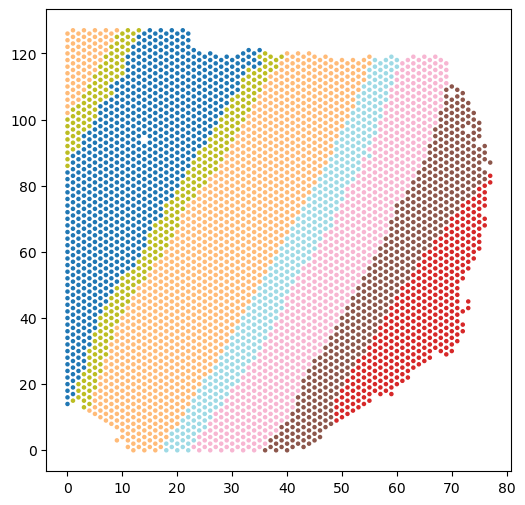

In [29]:
visualize_Y("../../data/sample_151507_anno.h5")

y shape before filtering: (4839,)
mask length: 4839


/tmp/ipykernel_1588999/2751095567.py:2: H5pyDeprecationWarning: The default file mode will change to 'r' (read-only) in h5py 3.0. To suppress this warning, pass the mode you need to h5py.File(), or set the global default h5.get_config().default_file_mode, or set the environment variable H5PY_DEFAULT_READONLY=1. Available modes are: 'r', 'r+', 'w', 'w-'/'x', 'a'. See the docs for details.
  data = h5py.File(path)


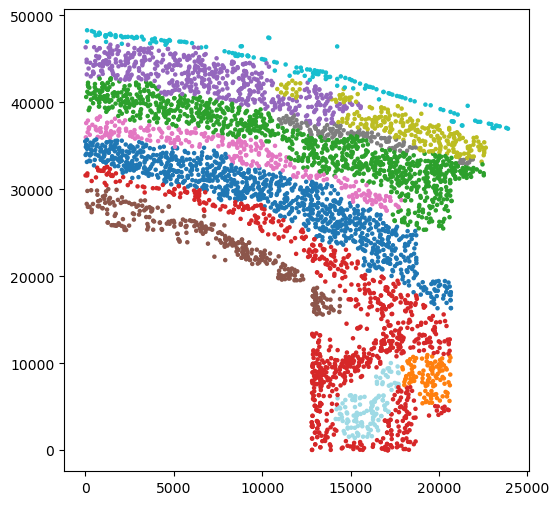

In [31]:
visualize_Y('../../data/osmFISH_cortex.h5')

In [ ]:
%%bash

cd "../../src"
./run.sh

In [ ]:
import os
import sys
sys.path.append(os.path.abspath('../../src'))
from utils import best_map


def visualize_preY(
        h5_path: str, 
        pred_path: str
    ) -> None:
    data = h5py.File(h5_path, 'r')
    x, y, pos = np.array(data['X']), np.array(data['Y']), np.array(data['Pos'])
    if pos.shape[1] != 2: pos = pos.T 
    f = np.where(y.astype(str) != 'NA')[0]
    y, pos = y[f].astype(str), pos[f].astype(float)
    codes, uniques = pd.factorize(y)
    pred = np.loadtxt(pred_path).astype(int)
    assert len(pred) == len(pos)
    pred_aligned = best_map(codes, pred).astype(int)
    plt.figure(figsize=(6, 6))
    plt.scatter(pos[:,0], pos[:,1], c=pred_aligned, s=5, cmap='tab20')

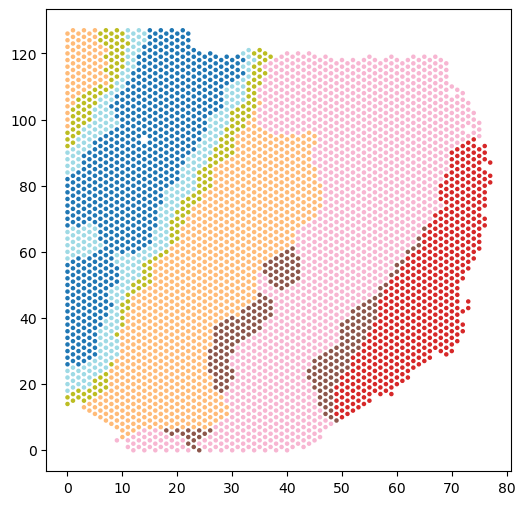

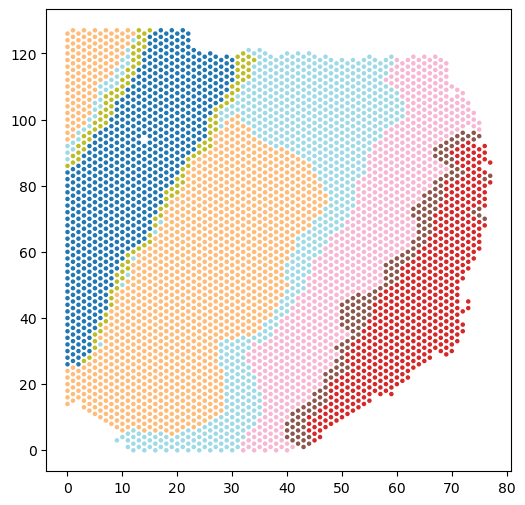

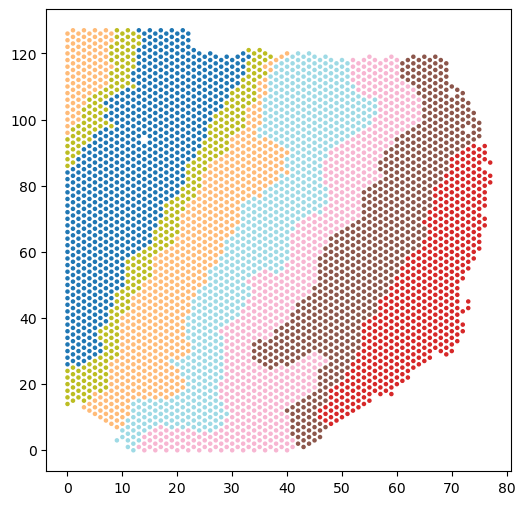

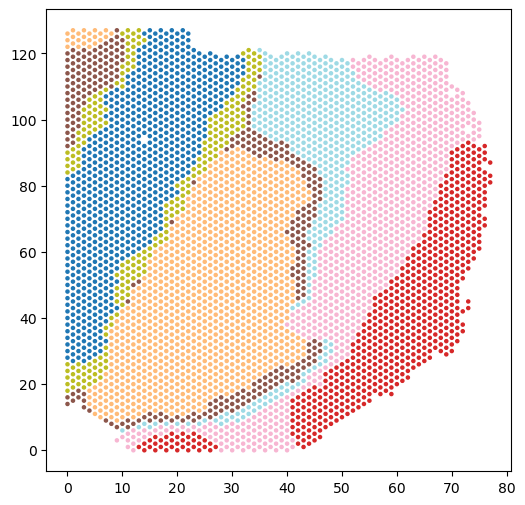

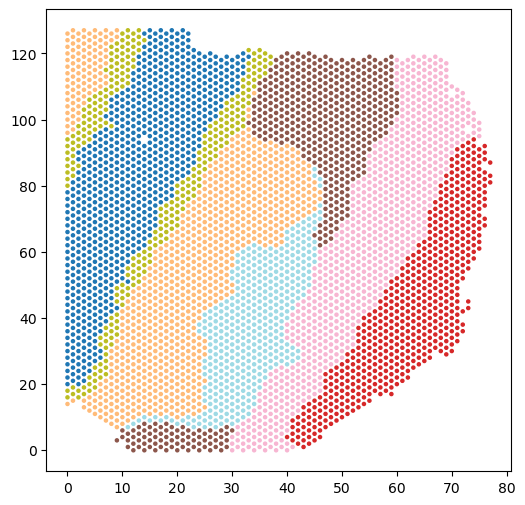

In [62]:
for seed in range(1001, 1006):
    visualize_preY(
        "../../data/sample_151507_anno.h5",
        f"../../src/out_151507/pred.csv_{seed}"
    )

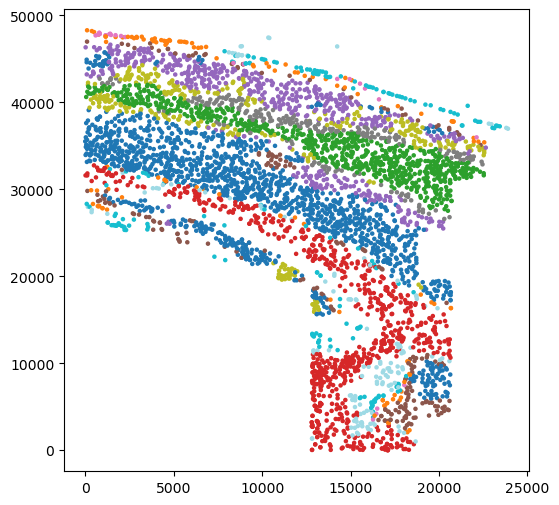

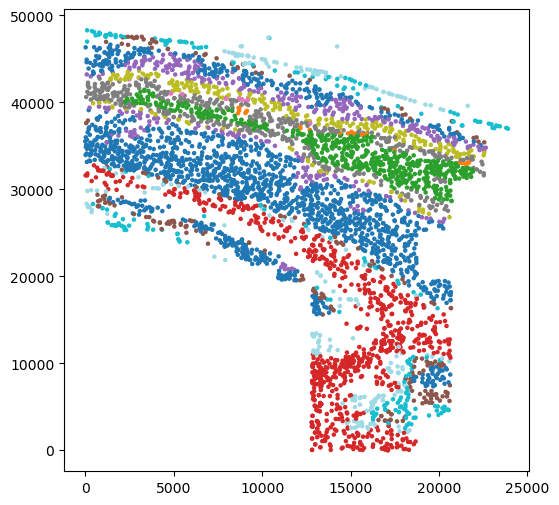

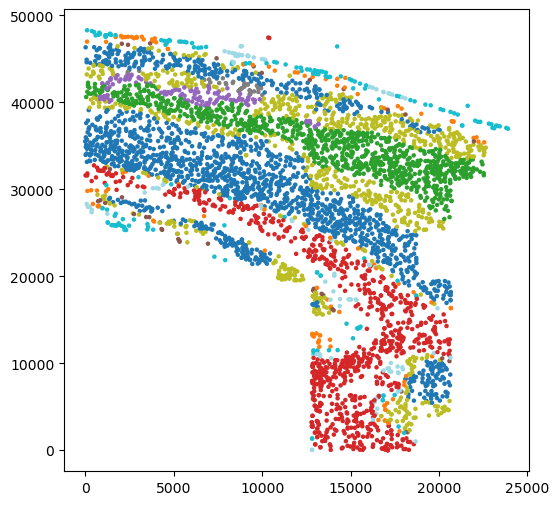

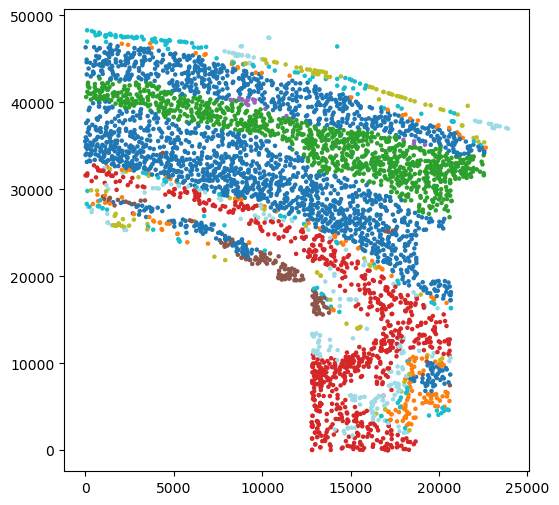

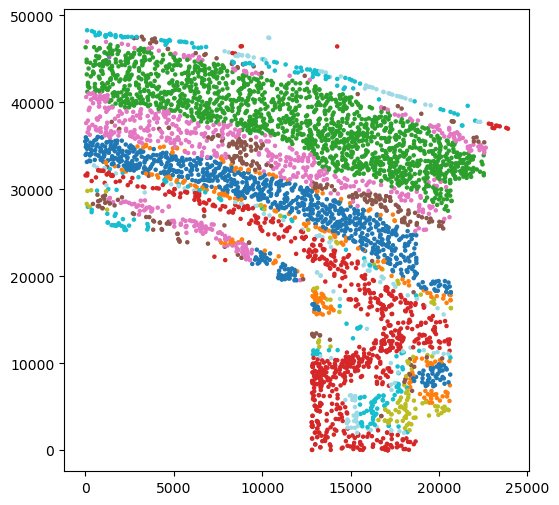

In [63]:
for seed in range(1001, 1006):    
    visualize_preY(
        "../../data/osmFISH_cortex.h5",
        f"../../src/out_osmFISH/pred.csv_{seed}"
    )

## Metrics with variance (ACC/NMI/ARI/kNN ACC/Moran's I)

仅依赖 h5（真值 Y + 空间坐标 Pos）和 out_*/pred.csv_*，复刻 run_DSSC.py 的评估。seeds 对应 run.sh 中的 1001..1005（文件后缀是 seed，不是 run 序号）。

In [41]:
import os
import sys
import numpy as np
import pandas as pd
import h5py
from scipy import spatial
from sklearn.neighbors import kneighbors_graph

sys.path.append(os.path.abspath('../../src'))
from utils import eval_cluster, knn_ACC, Iscore_label

/home/liuzy/Software/miniconda3/envs/dssc-4090/lib/python3.8/site-packages/setuptools_scm/_integration/setuptools.py:31: RuntimeWarning: 
ERROR: setuptools==59.8.0 is used in combination with setuptools_scm>=8.x

Your build configuration is incomplete and previously worked by accident!
setuptools_scm requires setuptools>=61

Suggested workaround if applicable:
 - migrating from the deprecated setup_requires mechanism to pep517/518
   and using a pyproject.toml to declare build dependencies
   which are reliably pre-installed before running the build tools

  warnings.warn(


In [42]:
def load_origin_reference(h5_path):
    with h5py.File(h5_path, 'r') as f:
        y = np.array(f['Y'])
        pos = np.array(f['Pos'])
    if pos.shape[1] != 2:
        pos = pos.T
    keep = np.where(y.astype(str) != 'NA')[0]
    y_true = pd.factorize(y[keep].astype(str))[0]
    pos = pos[keep].astype(float)
    return y_true, pos


def build_spatial_neighbor_graphs(pos, k0=20):
    A0 = kneighbors_graph(pos, k0, mode='connectivity', metric='euclidean',
                          include_self=False, n_jobs=-1).toarray()
    dist = spatial.distance_matrix(pos, pos)
    p_ = [np.argpartition(dist[i], k0)[:k0] for i in range(dist.shape[0])]
    return A0, p_

In [43]:
def evaluate_prediction(y_true, y_pred, p_, A0):
    acc, nmi, ari = eval_cluster(y_true, y_pred)
    return {
        'ACC': acc,
        'NMI': nmi,
        'ARI': ari,
        'kNN_ACC': knn_ACC(p_, y_pred),
        'MoranI': Iscore_label(y_pred + 1.0, A0),
    }


def evaluate_dataset(h5_path, save_dir, seeds=range(1001, 1006), pred_prefix='pred.csv_'):
    y_true, pos = load_origin_reference(h5_path)
    A0, p_ = build_spatial_neighbor_graphs(pos)
    rows = []
    for s in seeds:
        y_pred = np.loadtxt(os.path.join(save_dir, pred_prefix + str(s))).astype(int)
        assert len(y_pred) == len(y_true), 'seed %s length %d != %d' % (s, len(y_pred), len(y_true))
        rows.append(dict(seed=s, **evaluate_prediction(y_true, y_pred, p_, A0)))
    return pd.DataFrame(rows)


def summarize_runs(df):
    return df.drop(columns='seed').agg(['mean', 'std']).T

In [ ]:
DATASETS = {
    '151507': ('../../data/sample_151507_anno.h5', '../../src/out_151507'),
    'osmFISH': ('../../data/osmFISH_cortex.h5', '../../src/out_osmFISH'),
}

for name, (h5_path, save_dir) in DATASETS.items():
    df = evaluate_dataset(h5_path, save_dir)
    print('=== %s ===' % name)
    display(df.set_index('seed'))
    print('mean +/- std')
    display(summarize_runs(df))
    df.to_csv('./metadata/metrics_%s.csv' % name, index=False)

/hdd2/liuzy/Projects/IntensiveStudy4Lin/DSSC/src/utils.py:94: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  l_mode = stats.mode(labels).mode[0]
/hdd2/liuzy/Projects/IntensiveStudy4Lin/DSSC/src/utils.py:94: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  l_mode = sta

=== 151507 ===


,ACC,NMI,ARI,kNN_ACC,MoranI
seed,,,,,
1001,0.666193,0.617525,0.501984,0.956408,0.844646
1002,0.689647,0.633116,0.525156,0.948590,0.850036
1003,0.620706,0.679682,0.546764,0.968491,0.839363
1004,0.627339,0.561645,0.494114,0.958778,0.843580
1005,0.666430,0.667608,0.569573,0.972045,0.862710


mean +/- std


,mean,std
ACC,0.654063,0.029125
NMI,0.631915,0.046642
ARI,0.527518,0.031274
kNN_ACC,0.960862,0.009461
MoranI,0.848067,0.009026


/hdd2/liuzy/Projects/IntensiveStudy4Lin/DSSC/src/utils.py:94: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  l_mode = stats.mode(labels).mode[0]
/hdd2/liuzy/Projects/IntensiveStudy4Lin/DSSC/src/utils.py:94: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  l_mode = sta

=== osmFISH ===


,ACC,NMI,ARI,kNN_ACC,MoranI
seed,,,,,
1001,0.620169,0.530284,0.503870,0.882000,0.769901
1002,0.561273,0.515855,0.427880,0.878901,0.755032
1003,0.584418,0.495673,0.431815,0.905972,0.806603
1004,0.587725,0.531093,0.403438,0.912792,0.837714
1005,0.547840,0.544207,0.458345,0.891507,0.802253


mean +/- std


,mean,std
ACC,0.580285,0.027737
NMI,0.523423,0.018474
ARI,0.445070,0.038204
kNN_ACC,0.894234,0.014785
MoranI,0.794300,0.032545


In [ ]:
DATASETS = {
    '151507': ('../../data/sample_151507_anno.h5', '../../src/out_151507'),
    'osmFISH': ('../../data/osmFISH_cortex.h5', '../../src/out_osmFISH'),
}

for name, (h5_path, save_dir) in DATASETS.items():
    df = evaluate_dataset(h5_path, save_dir)
    print('=== %s ===' % name)
    display(df.set_index('seed'))
    print('mean +/- std')
    display(summarize_runs(df))
    df.to_csv('metrics_%s.csv' % name, index=False)

x 轴为 5 个指标，每根条形高度为该指标在 5 个 seed 上的均值，误差线为跨 seed 的标准差。

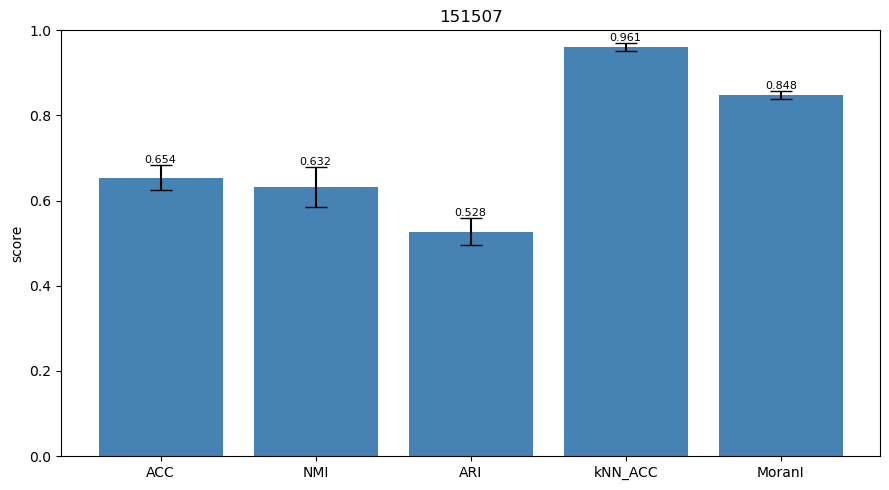

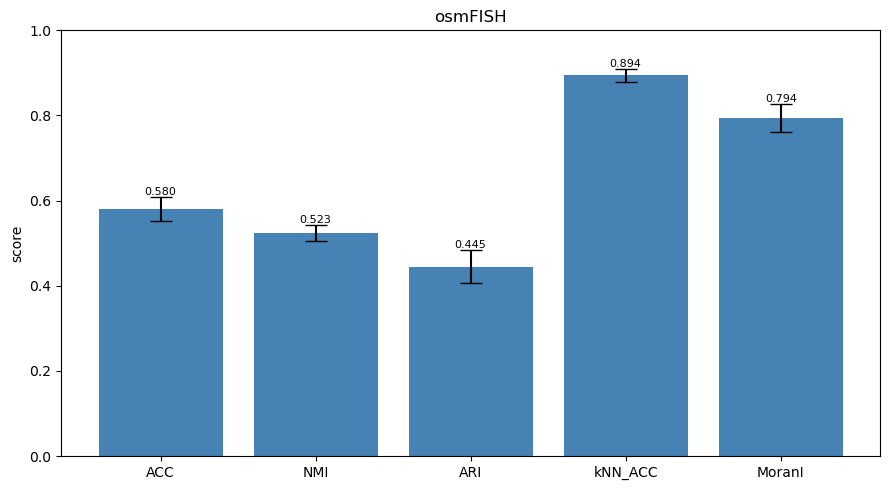

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

METRICS = ['ACC', 'NMI', 'ARI', 'kNN_ACC', 'MoranI']
METRIC_FILES = {
    '151507': './metadata/metrics_151507.csv',
    'osmFISH': './metadata/metrics_osmFISH.csv',
}


def plot_metrics_bar(csv_path, title, metrics=METRICS, ylim=(0, 1)):
    df = pd.read_csv(csv_path)
    means = [df[m].mean() for m in metrics]
    stds = [df[m].std() for m in metrics]
    x = np.arange(len(metrics))
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(x, means, yerr=stds, capsize=8, color='steelblue')
    for xi, mean, std in zip(x, means, stds):
        ax.text(xi, mean + std, '%.3f' % mean, ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics)
    ax.set_ylabel('score')
    ax.set_ylim(*ylim)
    ax.set_title(title)
    fig.tight_layout()
    return fig, ax


for name, path in METRIC_FILES.items():
    fig, ax = plot_metrics_bar(path, name)
    fig.savefig('./figures/bar_%s.png' % name, dpi=150)

plt.show()
